In [1]:
%pip install mysql-connector-python pandas plotly



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import getpass
import mysql.connector
from mysql.connector import Error
import pandas as pd
import plotly.express as px
from datetime import datetime

DB_HOST = "localhost"
DB_USER = input("MySQL username (usually root): ").strip()
DB_PASSWORD = getpass.getpass("MySQL password: ")
DB_NAME = "CampusCrew"

try:
    server_conn = mysql.connector.connect(
        host=DB_HOST,
        user=DB_USER,
        password=DB_PASSWORD
    )
    server_cursor = server_conn.cursor()
    server_cursor.execute(f"CREATE DATABASE IF NOT EXISTS `{DB_NAME}`")
    server_conn.commit()
    server_cursor.close()
    server_conn.close()

    conn = mysql.connector.connect(
        host=DB_HOST,
        user=DB_USER,
        password=DB_PASSWORD,
        database=DB_NAME
    )
    print("Connected to the CampusCrew database.")
except Error as e:
    print("Could not connect to MySQL:", e)
    print("Check that MySQL is running and that the username/password are correct.")

MySQL username (usually root):  root
MySQL password:  ········


Connected to the CampusCrew database.


In [3]:
def create_tables(connection):
    statements = [
        """
        CREATE TABLE IF NOT EXISTS clubs (
            club_id INT AUTO_INCREMENT PRIMARY KEY,
            club_name VARCHAR(100) NOT NULL UNIQUE,
            category VARCHAR(100) NOT NULL
        )
        """,
        """
        CREATE TABLE IF NOT EXISTS volunteers (
            volunteer_id INT AUTO_INCREMENT PRIMARY KEY,
            name VARCHAR(100) NOT NULL,
            email VARCHAR(150) NOT NULL UNIQUE,
            skills VARCHAR(300) DEFAULT '',
            preferred_role VARCHAR(50) DEFAULT ''
        )
        """,
        """
        CREATE TABLE IF NOT EXISTS events (
            event_id INT AUTO_INCREMENT PRIMARY KEY,
            club_id INT NOT NULL,
            title VARCHAR(150) NOT NULL,
            start_time DATETIME NOT NULL,
            end_time DATETIME NOT NULL,
            location VARCHAR(150) DEFAULT '',
            FOREIGN KEY (club_id) REFERENCES clubs(club_id),
            UNIQUE KEY unique_club_event (club_id, title, start_time)
        )
        """,
        """
        CREATE TABLE IF NOT EXISTS roles (
            role_id INT AUTO_INCREMENT PRIMARY KEY,
            event_id INT NOT NULL,
            role_name VARCHAR(60) NOT NULL,
            required_count INT NOT NULL DEFAULT 1,
            FOREIGN KEY (event_id) REFERENCES events(event_id) ON DELETE CASCADE,
            UNIQUE KEY unique_event_role (event_id, role_name)
        )
        """,
        """
        CREATE TABLE IF NOT EXISTS assignments (
            assignment_id INT AUTO_INCREMENT PRIMARY KEY,
            volunteer_id INT NOT NULL,
            role_id INT NOT NULL,
            status VARCHAR(20) NOT NULL DEFAULT 'assigned',
            attended TINYINT(1) DEFAULT NULL,
            hours_worked DECIMAL(5,2) DEFAULT 0,
            assigned_at TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
            FOREIGN KEY (volunteer_id) REFERENCES volunteers(volunteer_id),
            FOREIGN KEY (role_id) REFERENCES roles(role_id),
            UNIQUE KEY unique_volunteer_role (volunteer_id, role_id)
        )
        """
    ]
    cur = connection.cursor()
    for statement in statements:
        cur.execute(statement)
    connection.commit()
    cur.close()
    print("Tables are ready.")

create_tables(conn)

Tables are ready.


In [4]:
class CampusCrew:
    def __init__(self, connection):
        self.conn = connection

    def execute(self, sql, values=()):
        cur = self.conn.cursor()
        cur.execute(sql, values)
        self.conn.commit()
        result = cur.lastrowid
        cur.close()
        return result

    def query(self, sql, values=()):
        cur = self.conn.cursor(dictionary=True)
        cur.execute(sql, values)
        rows = cur.fetchall()
        cur.close()
        return rows

    def query_df(self, sql, values=()):
        return pd.DataFrame(self.query(sql, values))

    def seed_clubs(self):
        clubs = [
            ("Trendles", "Social"),
            ("Wildbeats", "Cultural"),
            ("GDG", "Technology"),
            ("Coders Club", "Technology"),
            ("BetaLabs", "Technology"),
            ("Cybersecurity Club", "Cybersecurity"),
            ("Enigma", "Technical"),
            ("Elix", "Technical")
        ]
        for name, category in clubs:
            self.execute(
                "INSERT INTO clubs (club_name, category) VALUES (%s, %s) "
                "ON DUPLICATE KEY UPDATE category=VALUES(category)",
                (name, category)
            )
        print("Club records added/checked.")

    def add_club(self, club_name, category):
        if not club_name.strip() or not category.strip():
            raise ValueError("Club name and category are required.")
        return self.execute(
            "INSERT INTO clubs (club_name, category) VALUES (%s, %s) "
            "ON DUPLICATE KEY UPDATE category=VALUES(category)",
            (club_name.strip(), category.strip())
        )

    def add_volunteer(self, name, email, skills="", preferred_role=""):
        if not name.strip() or not email.strip():
            raise ValueError("Name and email are required.")
        return self.execute(
            """
            INSERT INTO volunteers (name, email, skills, preferred_role)
            VALUES (%s, %s, %s, %s)
            ON DUPLICATE KEY UPDATE
                name=VALUES(name), skills=VALUES(skills),
                preferred_role=VALUES(preferred_role)
            """,
            (name.strip(), email.strip().lower(), skills.strip(), preferred_role.strip())
        )

    def add_event(self, club_name, title, start_time, end_time, location,
                  tech_count=2, art_count=2, pr_count=2):
        start = datetime.strptime(start_time, "%Y-%m-%d %H:%M")
        end = datetime.strptime(end_time, "%Y-%m-%d %H:%M")
        if end <= start:
            raise ValueError("Event end time must be after start time.")

        club = self.query("SELECT club_id FROM clubs WHERE club_name=%s", (club_name,))
        if not club:
            raise ValueError("Club not found. Run seed_clubs() or check the club name.")

        self.execute(
            """
            INSERT INTO events (club_id, title, start_time, end_time, location)
            VALUES (%s, %s, %s, %s, %s)
            ON DUPLICATE KEY UPDATE
                location=VALUES(location), end_time=VALUES(end_time)
            """,
            (club[0]["club_id"], title, start, end, location)
        )
        event = self.query(
            "SELECT event_id FROM events WHERE club_id=%s AND title=%s AND start_time=%s",
            (club[0]["club_id"], title, start)
        )
        event_id = event[0]["event_id"]

        roles = [
            ("Tech", tech_count),
            ("Art", art_count),
            ("PR/Management", pr_count)
        ]
        for role_name, required in roles:
            if required < 0:
                raise ValueError("Required volunteer count cannot be negative.")
            self.execute(
                """
                INSERT INTO roles (event_id, role_name, required_count)
                VALUES (%s, %s, %s)
                ON DUPLICATE KEY UPDATE required_count=VALUES(required_count)
                """,
                (event_id, role_name, required)
            )
        print("Event and its volunteer roles are ready. Event ID:", event_id)
        return event_id

    def list_clubs(self):
        return self.query_df("SELECT club_id, club_name, category FROM clubs ORDER BY club_name")

    def list_events(self):
        return self.query_df(
            """
            SELECT e.event_id, c.club_name, e.title, e.start_time, e.end_time, e.location
            FROM events e JOIN clubs c ON e.club_id=c.club_id
            ORDER BY e.start_time
            """
        )

    def list_roles(self, event_id=None):
        sql = """
            SELECT r.role_id, e.title, r.role_name, r.required_count,
                   COUNT(CASE WHEN a.status <> 'cancelled' THEN a.assignment_id END) AS assigned_count
            FROM roles r
            JOIN events e ON e.event_id=r.event_id
            LEFT JOIN assignments a ON a.role_id=r.role_id
        """
        values = ()
        if event_id is not None:
            sql += " WHERE e.event_id=%s"
            values = (event_id,)
        sql += " GROUP BY r.role_id, e.title, r.role_name, r.required_count ORDER BY r.role_id"
        return self.query_df(sql, values)

    def list_volunteers(self):
        return self.query_df(
            "SELECT volunteer_id, name, email, skills, preferred_role FROM volunteers ORDER BY name"
        )

    def _role_event(self, role_id):
        rows = self.query(
            """
            SELECT r.role_id, r.role_name, r.required_count, e.event_id,
                   e.start_time, e.end_time, e.title
            FROM roles r JOIN events e ON e.event_id=r.event_id
            WHERE r.role_id=%s
            """,
            (role_id,)
        )
        if not rows:
            raise ValueError("Role ID not found.")
        return rows[0]

    def has_conflict(self, volunteer_id, start_time, end_time, exclude_role_id=None):
        sql = """
            SELECT e.title, e.start_time, e.end_time
            FROM assignments a
            JOIN roles r ON r.role_id=a.role_id
            JOIN events e ON e.event_id=r.event_id
            WHERE a.volunteer_id=%s
              AND a.status <> 'cancelled'
              AND e.start_time < %s
              AND e.end_time > %s
        """
        values = [volunteer_id, end_time, start_time]
        if exclude_role_id is not None:
            sql += " AND a.role_id <> %s"
            values.append(exclude_role_id)
        return self.query(sql, tuple(values))

    def recommend_volunteers(self, role_id):
        role = self._role_event(role_id)
        assigned = self.query(
            "SELECT COUNT(*) AS n FROM assignments WHERE volunteer_id=%s AND status <> 'cancelled'",
            (-1,)
        )
        candidates = self.query(
            """
            SELECT v.volunteer_id, v.name, v.skills, v.preferred_role,
                   COUNT(a.assignment_id) AS workload
            FROM volunteers v
            LEFT JOIN assignments a
              ON a.volunteer_id=v.volunteer_id AND a.status <> 'cancelled'
            GROUP BY v.volunteer_id, v.name, v.skills, v.preferred_role
            """
        )
        role_key = role["role_name"].lower().replace("/management", "")
        available = []
        for person in candidates:
            if self.has_conflict(person["volunteer_id"], role["start_time"], role["end_time"]):
                continue
            already = self.query(
                "SELECT assignment_id FROM assignments WHERE volunteer_id=%s AND role_id=%s",
                (person["volunteer_id"], role_id)
            )
            if already:
                continue
            skills = (person["skills"] or "").lower()
            pref = (person["preferred_role"] or "").lower()
            skill_match = int(role_key in skills or pref == role["role_name"].lower())
            available.append({
                "volunteer_id": person["volunteer_id"],
                "name": person["name"],
                "skills": person["skills"],
                "preferred_role": person["preferred_role"],
                "skill_match": skill_match,
                "current_assignments": int(person["workload"])
            })
        available.sort(key=lambda x: (-x["skill_match"], x["current_assignments"], x["name"]))
        return pd.DataFrame(available)

    def assign_volunteer(self, role_id, volunteer_id):
        role = self._role_event(role_id)
        volunteer = self.query(
            "SELECT volunteer_id, name FROM volunteers WHERE volunteer_id=%s",
            (volunteer_id,)
        )
        if not volunteer:
            raise ValueError("Volunteer ID not found.")

        current = self.query(
            "SELECT COUNT(*) AS n FROM assignments WHERE role_id=%s AND status <> 'cancelled'",
            (role_id,)
        )[0]["n"]
        if current >= role["required_count"]:
            raise ValueError("This role is already full.")

        duplicate = self.query(
            "SELECT assignment_id FROM assignments WHERE volunteer_id=%s AND role_id=%s",
            (volunteer_id, role_id)
        )
        if duplicate:
            raise ValueError("This volunteer is already assigned to this role.")

        conflicts = self.has_conflict(volunteer_id, role["start_time"], role["end_time"])
        if conflicts:
            conflict_titles = ", ".join(row["title"] for row in conflicts)
            raise ValueError("Schedule conflict with: " + conflict_titles)

        assignment_id = self.execute(
            "INSERT INTO assignments (volunteer_id, role_id) VALUES (%s, %s)",
            (volunteer_id, role_id)
        )
        print(f"{volunteer[0]['name']} assigned to {role['role_name']} for {role['title']}.")
        return assignment_id

    def mark_attendance(self, assignment_id, attended, hours_worked=0):
        if hours_worked < 0:
            raise ValueError("Hours worked cannot be negative.")
        self.execute(
            """
            UPDATE assignments
            SET attended=%s, hours_worked=%s,
                status=CASE WHEN %s=1 THEN 'attended' ELSE 'absent' END
            WHERE assignment_id=%s
            """,
            (int(attended), hours_worked, int(attended), assignment_id)
        )
        print("Attendance updated.")

    def cancel_assignment(self, assignment_id):
        self.execute(
            "UPDATE assignments SET status='cancelled' WHERE assignment_id=%s",
            (assignment_id,)
        )
        print("Assignment cancelled.")

In [5]:
app = CampusCrew(conn)


app.seed_clubs()


while True:
    club_name = input("New club name (leave blank to skip/finish): ").strip()
    if not club_name:
        break
    category = input("Category for this club: ").strip()
    try:
        app.add_club(club_name, category)
        print(f"Club '{club_name}' saved.")
    except (ValueError, Error) as e:
        print("Club not added:", e)

app.list_clubs()


Club records added/checked.


New club name (leave blank to skip/finish):   


,club_id,club_name,category
0,5,BetaLabs,Technology
1,4,Coders Club,Technology
2,6,Cybersecurity Club,Cybersecurity
3,8,Elix,Technical
4,7,Enigma,Technical
5,3,GDG,Technology
6,1,Trendles,Social
7,2,Wildbeats,Cultural


In [6]:
VALID_ROLES = {"tech": "Tech", "art": "Art", "pr/management": "PR/Management", "pr": "PR/Management"}

while True:
    name = input("Volunteer name (leave blank to finish): ").strip()
    if not name:
        break
    email = input("Email: ").strip()
    if "@" not in email:
        print("That doesn't look like a valid email. Volunteer not added.\n")
        continue
    skills = input("Skills (comma-separated, e.g. python, design): ").strip()
    role_in = input("Preferred role (Tech / Art / PR/Management, or leave blank): ").strip()
    preferred_role = VALID_ROLES.get(role_in.lower(), "")
    if role_in and not preferred_role:
        print("Unrecognised role, saving with no preferred role.")

    try:
        app.add_volunteer(name, email, skills, preferred_role)
        print(f"Saved volunteer: {name}\n")
    except (ValueError, Error) as e:
        print("Volunteer not added:", e, "\n")

app.list_volunteers()


Volunteer name (leave blank to finish):  Lipika
Email:  lipikavinod05@gmail.com
Skills (comma-separated, e.g. python, design):  design
Preferred role (Tech / Art / PR/Management, or leave blank):  Tech


Saved volunteer: Lipika



Volunteer name (leave blank to finish):  


,volunteer_id,name,email,skills,preferred_role
0,4,Arjun Nair,arjun.demo@example.com,"python, networking, cybersecurity",Tech
1,1,Asha Menon,asha.demo@example.com,"python, coding, debugging",Tech
2,5,Lipika,lipikavinod05@gmail.com,design,Tech
3,3,Neha Thomas,neha.demo@example.com,"publicity, communication, management",PR/Management
4,2,Rahul Das,rahul.demo@example.com,"art, design, posters",Art


In [9]:
def ask_datetime(prompt):
    while True:
        value = input(prompt + " (format YYYY-MM-DD HH:MM, e.g. 2026-11-10 10:00): ").strip()
        try:
            datetime.strptime(value, "%Y-%m-%d %H:%M")
            return value
        except ValueError:
            print("Wrong format, try again.")

def ask_count(prompt):
    while True:
        value = input(prompt + " (number, default 0): ").strip()
        if value == "":
            return 0
        if value.isdigit():
            return int(value)
        print("Please enter a whole number.")

event_id = None

while True:
    print("\nAvailable clubs:")
    print(app.list_clubs().to_string(index=False))

    club_name = input("\nClub name for the event (leave blank to finish): ").strip()
    if not club_name:
        break

    title = input("Event title: ").strip()
    start_time = ask_datetime("Start time")
    end_time = ask_datetime("End time")
    location = input("Location: ").strip()
    tech_count = ask_count("Tech volunteers needed")
    art_count = ask_count("Art volunteers needed")
    pr_count = ask_count("PR/Management volunteers needed")

    try:
        event_id = app.add_event(club_name, title, start_time, end_time, location,
                                 tech_count, art_count, pr_count)
    except (ValueError, Error) as e:
        print("Event not added:", e)

app.list_events()



Available clubs:
 club_id          club_name      category
       5           BetaLabs    Technology
       4        Coders Club    Technology
       6 Cybersecurity Club Cybersecurity
       8               Elix     Technical
       7             Enigma     Technical
       3                GDG    Technology
       1           Trendles        Social
       2          Wildbeats      Cultural



Club name for the event (leave blank to finish):  


,event_id,club_name,title,start_time,end_time,location
0,1,Coders Club,Python Project Workshop,2026-11-10 10:00:00,2026-11-10 12:00:00,Computer Lab


In [10]:
display(app.list_events())
choice = input("Event ID to show roles for (press Enter to use the last event you added): ").strip()
if choice:
    event_id = int(choice)

if event_id is None:
    print("No event selected yet. Add an event in the previous step first.")
else:
    display(app.list_roles(event_id))


,event_id,club_name,title,start_time,end_time,location
0,1,Coders Club,Python Project Workshop,2026-11-10 10:00:00,2026-11-10 12:00:00,Computer Lab


Event ID to show roles for (press Enter to use the last event you added):  


No event selected yet. Add an event in the previous step first.


In [11]:
# Use a role_id from the roles table above
role_id = int(input("Enter the role ID to get volunteer recommendations: "))
app.recommend_volunteers(role_id)


Enter the role ID to get volunteer recommendations:  


ValueError: invalid literal for int() with base 10: ''

In [12]:
role_id = int(input("Enter role ID: "))
volunteer_id = int(input("Enter volunteer ID: "))

try:
    assignment_id = app.assign_volunteer(role_id, volunteer_id)
    print("Assignment ID:", assignment_id)
except (ValueError, Error) as e:
    print("Assignment was not created:", e)

Enter role ID:  1
Enter volunteer ID:  2


Assignment was not created: This volunteer is already assigned to this role.


In [13]:
assignments_df = app.query_df(
    """
    SELECT a.assignment_id, v.name AS volunteer, v.email,
           e.title AS event, r.role_name AS role,
           e.start_time, e.end_time, a.status, a.attended, a.hours_worked
    FROM assignments a
    JOIN volunteers v ON v.volunteer_id=a.volunteer_id
    JOIN roles r ON r.role_id=a.role_id
    JOIN events e ON e.event_id=r.event_id
    ORDER BY e.start_time, r.role_name, v.name
    """
)
assignments_df

,assignment_id,volunteer,email,event,role,start_time,end_time,status,attended,hours_worked
0,1,Rahul Das,rahul.demo@example.com,Python Project Workshop,Tech,2026-11-10 10:00:00,2026-11-10 12:00:00,assigned,None,0.00


In [14]:
assignment_id = int(input("Enter assignment ID: "))
attended = int(input("Attendance (1 = present, 0 = absent): "))
hours_worked = float(input("Hours worked: "))

if attended not in (0, 1):
    print("Attendance must be 1 or 0.")
else:
    app.mark_attendance(assignment_id, attended, hours_worked)

KeyboardInterrupt: Interrupted by user

In [15]:
volunteer_analytics = app.query_df(
    """
    SELECT v.volunteer_id, v.name,
           COUNT(a.assignment_id) AS total_assignments,
           SUM(CASE WHEN a.attended=1 THEN 1 ELSE 0 END) AS attended_events,
           SUM(CASE WHEN a.attended=0 THEN 1 ELSE 0 END) AS absences,
           COALESCE(SUM(a.hours_worked), 0) AS total_hours,
           CASE
             WHEN SUM(CASE WHEN a.attended IS NOT NULL THEN 1 ELSE 0 END) = 0 THEN NULL
             ELSE ROUND(
               100.0 * SUM(CASE WHEN a.attended=1 THEN 1 ELSE 0 END) /
               SUM(CASE WHEN a.attended IS NOT NULL THEN 1 ELSE 0 END), 2
             )
           END AS attendance_percentage
    FROM volunteers v
    LEFT JOIN assignments a
      ON a.volunteer_id=v.volunteer_id AND a.status <> 'cancelled'
    GROUP BY v.volunteer_id, v.name
    ORDER BY total_assignments DESC, v.name
    """
)
volunteer_analytics

,volunteer_id,name,total_assignments,attended_events,absences,total_hours,attendance_percentage
0,2,Rahul Das,1,0,0,0.00,None
1,4,Arjun Nair,0,0,0,0.00,None
2,1,Asha Menon,0,0,0,0.00,None
3,3,Neha Thomas,0,0,0,0.00,None


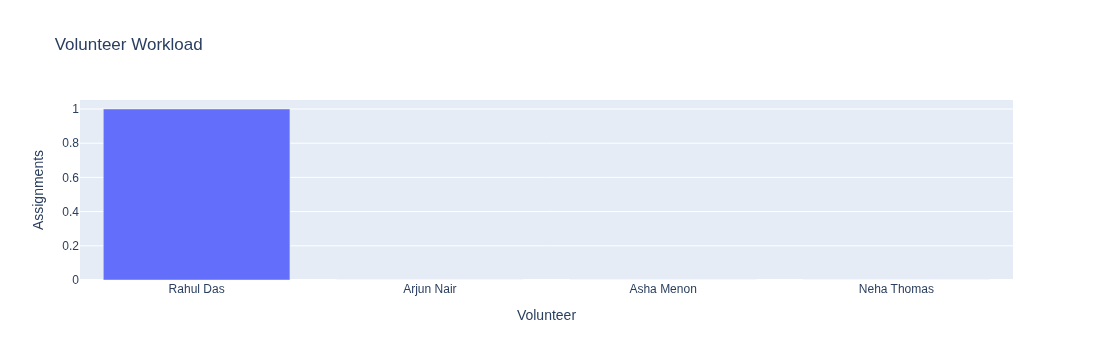

In [16]:
if not volunteer_analytics.empty:
    chart_data = volunteer_analytics.copy()
    fig = px.bar(
        chart_data,
        x="name",
        y="total_assignments",
        title="Volunteer Workload",
        labels={"name": "Volunteer", "total_assignments": "Assignments"}
    )
    fig.show()
else:
    print("No volunteer records available yet.")

In [17]:
attendance_data = volunteer_analytics.dropna(subset=["attendance_percentage"])
if not attendance_data.empty:
    fig = px.bar(
        attendance_data,
        x="name",
        y="attendance_percentage",
        title="Volunteer Attendance Percentage",
        labels={"name": "Volunteer", "attendance_percentage": "Attendance (%)"},
        range_y=[0, 100]
    )
    fig.show()
else:
    print("Record attendance for at least one assignment to create this chart.")

Record attendance for at least one assignment to create this chart.


In [18]:
role_report = app.query_df(
    """
    SELECT e.title AS event, r.role_name, r.required_count,
           COUNT(CASE WHEN a.status <> 'cancelled' THEN a.assignment_id END) AS assigned_count,
           GREATEST(
               r.required_count -
               COUNT(CASE WHEN a.status <> 'cancelled' THEN a.assignment_id END),
               0
           ) AS unfilled_positions
    FROM roles r
    JOIN events e ON e.event_id=r.event_id
    LEFT JOIN assignments a ON a.role_id=r.role_id
    GROUP BY r.role_id, e.title, r.role_name, r.required_count
    ORDER BY unfilled_positions DESC, e.title
    """
)
role_report

,event,role_name,required_count,assigned_count,unfilled_positions
0,Python Project Workshop,Tech,2,1,1
1,Python Project Workshop,Art,1,0,1
2,Python Project Workshop,PR/Management,1,0,1


In [19]:
test_volunteer_id = int(input("Volunteer ID to test: "))
test_role_id = int(input("Role ID whose event time should be checked: "))
test_role = app._role_event(test_role_id)
conflicts = app.has_conflict(
    test_volunteer_id,
    test_role["start_time"],
    test_role["end_time"]
)

if conflicts:
    print("Conflict detected:")
    display(pd.DataFrame(conflicts))
else:
    print("No scheduling conflict found for this time range.")

Volunteer ID to test:  1
Role ID whose event time should be checked:  2


No scheduling conflict found for this time range.


In [20]:
volunteer_analytics.to_csv("campuscrew_volunteer_analytics.csv", index=False)
role_report.to_csv("campuscrew_role_capacity_report.csv", index=False)
print("Reports exported to the notebook's current working directory.")


Reports exported to the notebook's current working directory.


In [21]:
if "conn" in globals() and conn.is_connected():
    conn.close()
    print("MySQL connection closed.")

MySQL connection closed.
